In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nobinn/picture-to-test-output/Te-gl_0015 (1).jpg
/kaggle/input/datasets/nobinn/picture-to-test-output/Te-meTr_0001.jpg
/kaggle/input/datasets/nobinn/picture-to-test-output/Te-noTr_0004.jpg
/kaggle/input/datasets/nobinn/picture-to-test-output/Te-piTr_0003.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_124.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_949.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_786.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_371.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_599.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_802.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary/Tr-pi_1323.jpg
/kaggle/input/datasets/masoudnickparva

In [2]:
import os, shutil, hashlib, random, json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix


SEED = 123
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

In [3]:
RAW_TRAIN = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training'
RAW_TEST  = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing'

WORK = '/kaggle/working'
CLEAN_ROOT  = f'{WORK}/clean'
CLEAN_TRAIN = f'{CLEAN_ROOT}/Training'
CLEAN_TEST  = f'{CLEAN_ROOT}/Testing'
MODEL_PATH  = f'{WORK}/best_resnet50.keras'

def list_images(root):
    
    out = []
    for cls in sorted(os.listdir(root)):
        d = os.path.join(root, cls)
        if os.path.isdir(d):
            for fn in sorted(os.listdir(d)):
                out.append((cls, fn, os.path.join(d, fn)))
    return out


for name, root in [('Training', RAW_TRAIN), ('Testing', RAW_TEST)]:
    counts = Counter(cls for cls, _, _ in list_images(root))
    print(name, dict(counts), 'মোট:', sum(counts.values()))

Training {'glioma': 1400, 'meningioma': 1400, 'notumor': 1400, 'pituitary': 1400} মোট: 5600
Testing {'glioma': 400, 'meningioma': 400, 'notumor': 400, 'pituitary': 400} মোট: 1600


In [4]:

def file_hash(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def clean_copy(src_root, dst_root):
 
    seen, kept, removed = set(), 0, 0
    for cls, fn, src in list_images(src_root):
        dst_dir = os.path.join(dst_root, cls)
        os.makedirs(dst_dir, exist_ok=True)
        h = file_hash(src)
        if h in seen:
            removed += 1
            continue
        seen.add(h)
        shutil.copy(src, os.path.join(dst_dir, fn))
        kept += 1
    return kept, removed

if os.path.exists(CLEAN_ROOT):
    shutil.rmtree(CLEAN_ROOT)

k, r = clean_copy(RAW_TRAIN, CLEAN_TRAIN)
print(f'Training: keep {k}, removed {r}')
k, r = clean_copy(RAW_TEST, CLEAN_TEST)
print(f'Testing : keep {k}, removed {r}')


train_hashes = {file_hash(p) for _, _, p in list_images(CLEAN_TRAIN)}
overlap = [fn for _, fn, p in list_images(CLEAN_TEST) if file_hash(p) in train_hashes]
print('Train-test  overlap:', len(overlap))

Training: keep 5429, removed 171
Testing : keep 1584, removed 16
Train-test  overlap: 0


In [5]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    CLEAN_TRAIN,
    validation_split=0.2,
    subset='training',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    CLEAN_TRAIN,
    validation_split=0.2,
    subset='validation',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)


test_ds = tf.keras.utils.image_dataset_from_directory(
    CLEAN_TEST,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = test_ds.class_names      
NUM_CLASSES = len(class_names)
TEST_PATHS = list(test_ds.file_paths) 
print('Classes:', class_names)


for x, y in train_ds.take(1):
    print('Batch shape:', x.shape, '| min:', float(x.numpy().min()), '| max:', float(x.numpy().max()))

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 5429 files belonging to 4 classes.
Using 4344 files for training.


I0000 00:00:1793938180.928877      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793938180.932970      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 5429 files belonging to 4 classes.
Using 1085 files for validation.
Found 1584 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Batch shape: (32, 224, 224, 3) | min: 0.0 | max: 255.0


In [6]:
def build_model(num_classes):
    augmentation = tf.keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.10),
        layers.RandomTranslation(0.05, 0.05),
        layers.RandomContrast(0.10),
    ], name='augmentation')

    base = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base.trainable = False

    inputs = layers.Input(shape=(224, 224, 3))
    x = augmentation(inputs)
    x = preprocess_input(x)               
    x = base(x, training=False)             
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs, outputs), base

model, base_model = build_model(NUM_CLASSES)
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ augmentation[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ augmentation[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ augmentation[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    524,544 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 4)         │      1,028 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,113,284 (91.98 MB)

 Trainable params: 525,572 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [7]:
model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['sparse_categorical_accuracy']
)

callbacks_stage1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=4, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6
    ),
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks_stage1
)

Epoch 1/12
136/136 ━━━━━━━━━━━━━━━━━━━━ 37s 191ms/step - loss: 0.6955 - sparse_categorical_accuracy: 0.7516 - val_loss: 0.5100 - val_sparse_categorical_accuracy: 0.7770 - learning_rate: 0.0010
Epoch 2/12
136/136 ━━━━━━━━━━━━━━━━━━━━ 23s 170ms/step - loss: 0.4341 - sparse_categorical_accuracy: 0.8336 - val_loss: 0.6217 - val_sparse_categorical_accuracy: 0.7475 - learning_rate: 0.0010
Epoch 3/12
136/136 ━━━━━━━━━━━━━━━━━━━━ 25s 183ms/step - loss: 0.3893 - sparse_categorical_accuracy: 0.8467 - val_loss: 0.3614 - val_sparse_categorical_accuracy: 0.8479 - learning_rate: 0.0010
Epoch 4/12
136/136 ━━━━━━━━━━━━━━━━━━━━ 26s 192ms/step - loss: 0.3703 - sparse_categorical_accuracy: 0.8568 - val_loss: 0.3520 - val_sparse_categorical_accuracy: 0.8507 - learning_rate: 0.0010
Epoch 5/12
136/136 ━━━━━━━━━━━━━━━━━━━━ 24s 178ms/step - loss: 0.3437 - sparse_categorical_accuracy: 0.8646 - val_loss: 0.3382 - val_sparse_categorical_accuracy: 0.8645 - learning_rate: 0.0010
Epoch 6/12
136/136 ━━━━━━━━━━━━━━━━

In [8]:
base_model.trainable = True


for layer in base_model.layers[:-40]:
    layer.trainable = False


for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False


model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['sparse_categorical_accuracy']
)

callbacks_stage2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7
    ),
   
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_PATH, monitor='val_loss', save_best_only=True
    ),
]

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks_stage2
)

Epoch 1/20
136/136 ━━━━━━━━━━━━━━━━━━━━ 48s 278ms/step - loss: 0.2494 - sparse_categorical_accuracy: 0.9019 - val_loss: 0.2494 - val_sparse_categorical_accuracy: 0.9097 - learning_rate: 1.0000e-05
Epoch 2/20
136/136 ━━━━━━━━━━━━━━━━━━━━ 34s 250ms/step - loss: 0.1990 - sparse_categorical_accuracy: 0.9245 - val_loss: 0.2288 - val_sparse_categorical_accuracy: 0.9143 - learning_rate: 1.0000e-05
Epoch 3/20
136/136 ━━━━━━━━━━━━━━━━━━━━ 33s 245ms/step - loss: 0.1695 - sparse_categorical_accuracy: 0.9353 - val_loss: 0.2043 - val_sparse_categorical_accuracy: 0.9263 - learning_rate: 1.0000e-05
Epoch 4/20
136/136 ━━━━━━━━━━━━━━━━━━━━ 35s 256ms/step - loss: 0.1381 - sparse_categorical_accuracy: 0.9503 - val_loss: 0.1881 - val_sparse_categorical_accuracy: 0.9364 - learning_rate: 1.0000e-05
Epoch 5/20
136/136 ━━━━━━━━━━━━━━━━━━━━ 34s 247ms/step - loss: 0.1215 - sparse_categorical_accuracy: 0.9556 - val_loss: 0.1763 - val_sparse_categorical_accuracy: 0.9373 - learning_rate: 1.0000e-05
Epoch 6/20
136/

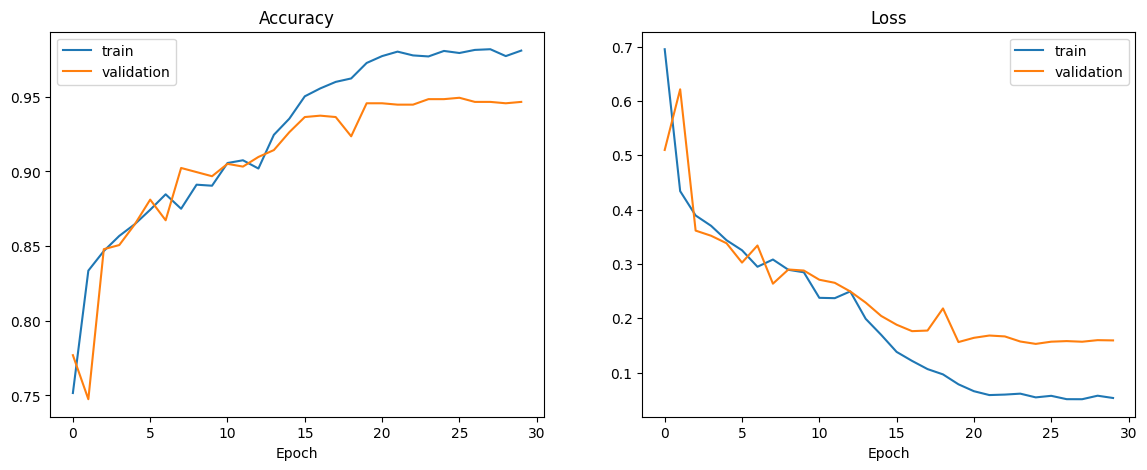

In [9]:
def plot_history(h1, h2):
    acc  = h1.history['sparse_categorical_accuracy'] + h2.history['sparse_categorical_accuracy']
    vacc = h1.history['val_sparse_categorical_accuracy'] + h2.history['val_sparse_categorical_accuracy']
    loss = h1.history['loss'] + h2.history['loss']
    vloss = h1.history['val_loss'] + h2.history['val_loss']

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(acc, label='train'); ax[0].plot(vacc, label='validation')
    ax[0].set_title('Accuracy'); ax[0].legend(); ax[0].set_xlabel('Epoch')
    ax[1].plot(loss, label='train'); ax[1].plot(vloss, label='validation')
    ax[1].set_title('Loss'); ax[1].legend(); ax[1].set_xlabel('Epoch')
    plt.show()

plot_history(history1, history2)

In [10]:
best_model = tf.keras.models.load_model(MODEL_PATH)

val_loss, val_acc = best_model.evaluate(val_ds, verbose=0)
print(f'Validation Accuracy: {val_acc:.4f} | Validation Loss: {val_loss:.4f}')

Validation Accuracy: 0.9484 | Validation Loss: 0.1528


In [11]:
test_loss, test_acc = best_model.evaluate(test_ds, verbose=0)
print(f'Test Accuracy: {test_acc:.4f}')

y_true = np.concatenate([y.numpy() for _, y in test_ds])
probs  = best_model.predict(test_ds, verbose=0)
y_pred = np.argmax(probs, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
print('Confusion matrix pred:')
print(pd.DataFrame(
    confusion_matrix(y_true, y_pred),
    index=[f'real_{c}' for c in class_names],
    columns=[f'pred_{c}' for c in class_names]
))

Test Accuracy: 0.9223
              precision    recall  f1-score   support

      glioma     0.9740    0.7772    0.8646       386
  meningioma     0.8528    0.9171    0.8838       398
     notumor     0.9366    0.9975    0.9661       400
   pituitary     0.9408    0.9925    0.9659       400

    accuracy                         0.9223      1584
   macro avg     0.9261    0.9211    0.9201      1584
weighted avg     0.9257    0.9223    0.9206      1584

Confusion matrix pred:
                 pred_glioma  pred_meningioma  pred_notumor  pred_pituitary
real_glioma              300               60            19               7
real_meningioma            8              365             8              17
real_notumor               0                0           399               1
real_pituitary             0                3             0             397


In [12]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 34s 247ms/step - loss: 0.0559 - sparse_categorical_accuracy: 0.9791 - val_loss: 0.1553 - val_sparse_categorical_accuracy: 0.9493
Epoch 2/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 32s 237ms/step - loss: 0.0534 - sparse_categorical_accuracy: 0.9809 - val_loss: 0.1560 - val_sparse_categorical_accuracy: 0.9484
Epoch 3/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 33s 240ms/step - loss: 0.0521 - sparse_categorical_accuracy: 0.9830 - val_loss: 0.1577 - val_sparse_categorical_accuracy: 0.9493
Epoch 4/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 33s 242ms/step - loss: 0.0518 - sparse_categorical_accuracy: 0.9816 - val_loss: 0.1562 - val_sparse_categorical_accuracy: 0.9484
Epoch 5/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 32s 238ms/step - loss: 0.0512 - sparse_categorical_accuracy: 0.9830 - val_loss: 0.1595 - val_sparse_categorical_accuracy: 0.9465


In [13]:
df = pd.DataFrame({
    'file': [os.path.basename(p) for p in TEST_PATHS],
    'real': [class_names[i] for i in y_true],
    'predicted': [class_names[i] for i in y_pred],
    'confidence(%)': np.round(probs.max(axis=1) * 100, 2),
})
df['correct'] = df['real'] == df['predicted']
df.to_csv(f'{WORK}/test_predictions_final.csv', index=False)
print('Saved: test_predictions_final.csv')

Saved: test_predictions_final.csv


In [14]:
info = {
    'model_file': 'best_resnet50.keras',
    'class_names': class_names,
    'img_size': IMG_SIZE,
    'seed': SEED,
    'test_accuracy': float(test_acc),
    'validation_accuracy': float(val_acc),
}
with open(f'{WORK}/model_info.json', 'w') as f:
    json.dump(info, f, indent=4)

for f_name in sorted(os.listdir(WORK)):
    p = os.path.join(WORK, f_name)
    if os.path.isfile(p):
        print(f'{f_name:35s} {os.path.getsize(p)/1024/1024:8.2f} MB')

best_resnet50.keras                   217.26 MB
model_info.json                         0.00 MB
test_predictions_final.csv              0.07 MB


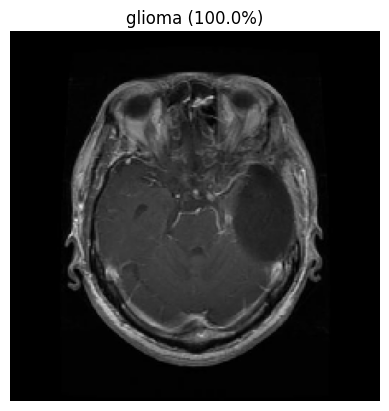

  glioma      : 100.00%
  meningioma  :   0.00%
  notumor     :   0.00%
  pituitary   :   0.00%


'glioma'

In [15]:
def predict_image(path, model=best_model):
    img = tf.keras.utils.load_img(path, target_size=IMG_SIZE)
    x = tf.keras.utils.img_to_array(img)              
    probs = model.predict(np.expand_dims(x, 0), verbose=0)[0]
    idx = int(np.argmax(probs))

    plt.imshow(np.array(img).astype('uint8'))
    plt.axis('off')
    plt.title(f'{class_names[idx]} ({probs[idx]*100:.1f}%)')
    plt.show()

    for name, p in zip(class_names, probs):
        print(f'  {name:12s}: {p*100:6.2f}%')
    return class_names[idx]

predict_image('/kaggle/input/datasets/nobinn/picture-to-test-output/Te-gl_0015 (1).jpg')

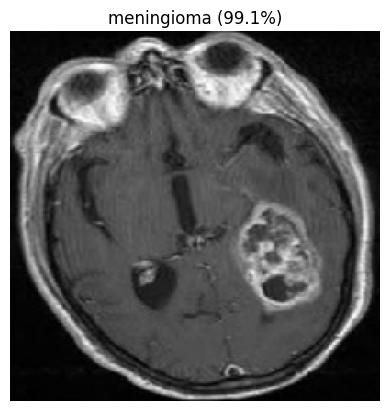

  glioma      :   0.01%
  meningioma  :  99.14%
  notumor     :   0.84%
  pituitary   :   0.01%


'meningioma'

In [16]:
def predict_image(path, model=best_model):
    img = tf.keras.utils.load_img(path, target_size=IMG_SIZE)
    x = tf.keras.utils.img_to_array(img)               
    probs = model.predict(np.expand_dims(x, 0), verbose=0)[0]
    idx = int(np.argmax(probs))

    plt.imshow(np.array(img).astype('uint8'))
    plt.axis('off')
    plt.title(f'{class_names[idx]} ({probs[idx]*100:.1f}%)')
    plt.show()

    for name, p in zip(class_names, probs):
        print(f'  {name:12s}: {p*100:6.2f}%')
    return class_names[idx]

predict_image('/kaggle/input/datasets/nobinn/picture-to-test-output/Te-meTr_0001.jpg')

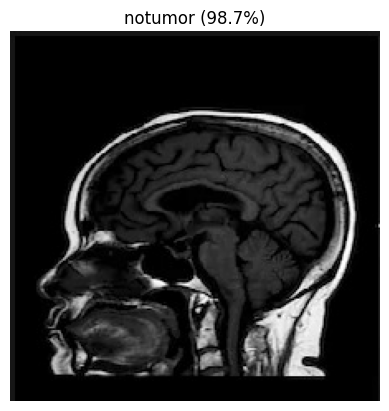

  glioma      :   0.01%
  meningioma  :   0.51%
  notumor     :  98.68%
  pituitary   :   0.80%


'notumor'

In [17]:
def predict_image(path, model=best_model):
    img = tf.keras.utils.load_img(path, target_size=IMG_SIZE)
    x = tf.keras.utils.img_to_array(img)              
    probs = model.predict(np.expand_dims(x, 0), verbose=0)[0]
    idx = int(np.argmax(probs))

    plt.imshow(np.array(img).astype('uint8'))
    plt.axis('off')
    plt.title(f'{class_names[idx]} ({probs[idx]*100:.1f}%)')
    plt.show()

    for name, p in zip(class_names, probs):
        print(f'  {name:12s}: {p*100:6.2f}%')
    return class_names[idx]

predict_image('/kaggle/input/datasets/nobinn/picture-to-test-output/Te-noTr_0004.jpg')

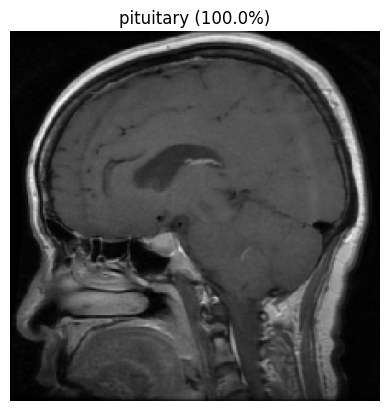

  glioma      :   0.00%
  meningioma  :   0.00%
  notumor     :   0.00%
  pituitary   : 100.00%


'pituitary'

In [18]:
def predict_image(path, model=best_model):
    img = tf.keras.utils.load_img(path, target_size=IMG_SIZE)
    x = tf.keras.utils.img_to_array(img)               
    probs = model.predict(np.expand_dims(x, 0), verbose=0)[0]
    idx = int(np.argmax(probs))

    plt.imshow(np.array(img).astype('uint8'))
    plt.axis('off')
    plt.title(f'{class_names[idx]} ({probs[idx]*100:.1f}%)')
    plt.show()

    for name, p in zip(class_names, probs):
        print(f'  {name:12s}: {p*100:6.2f}%')
    return class_names[idx]

predict_image('/kaggle/input/datasets/nobinn/picture-to-test-output/Te-piTr_0003.jpg')

In [19]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true, y_pred = [], []

for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(probabilities, axis=1))

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

print(confusion_matrix(y_true, y_pred))

              precision    recall  f1-score   support

      glioma       0.97      0.78      0.86       386
  meningioma       0.86      0.91      0.88       398
     notumor       0.93      1.00      0.96       400
   pituitary       0.93      0.99      0.96       400

    accuracy                           0.92      1584
   macro avg       0.92      0.92      0.92      1584
weighted avg       0.92      0.92      0.92      1584

[[301  58  20   7]
 [  9 361   8  20]
 [  0   0 399   1]
 [  0   2   0 398]]


SyntaxError: invalid syntax (3836552478.py, line 1)